# Part 3c — Specificity Control
Experiment ID: p3c-control-v1
Objective: test whether Part 3b's AUC=1.0 reflects safety-specific
detection or just narrow-vs-broad fine-tuning detection. New group:
"narrow-benign" (GSM8K, narrow/formulaic like AdvBench, but safe).
Compared against the EXISTING broad-benign (Alpaca) and malicious
(AdvBench poison) scores from Part 3b -- those are not re-run.

Reuses: layer=14, local_steps=5, the same probe set, the same locked
LoRA config, the same explicit-state-loading fix from 3b.

In [1]:
!pip install -q -U transformers accelerate bitsandbytes peft datasets scikit-learn
!pip install torch torchvision torchaudio
!pip uninstall -y torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 112.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 46.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 117.9 MB/s eta 0:00:00
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import sys
if "torchaudio" in sys.modules:
    del sys.modules["torchaudio"]

import os, json, random, datetime, copy
import numpy as np
import torch
from google.colab import drive
drive.mount('/content/drive')

CONFIG = {
    "experiment_id": "p3c-control-v1",
    "date": datetime.datetime.now(datetime.UTC).strftime("%Y-%m-%d"),
    "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
    "layer_index": 14, "local_steps": 5, "local_lr": 1e-4,
    "lora_r": 8, "lora_alpha": 16,
    "n_clients_per_group": 30,       # matches 3b exactly, for a fair comparison
    "seeds": [42, 43, 44],
    "n_probe_harmful": 32,
    "torch_dtype": "float16",
}

PROJECT_ROOT = "/content/drive/MyDrive/fedllm-safety-defense"
RESULTS_DIR = f"{PROJECT_ROOT}/results/part3c_specificity_control"
CKPT_DIR = f"{RESULTS_DIR}/checkpoints"
LOG_PATH = f"{PROJECT_ROOT}/experiment_log.csv"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)
print(json.dumps(CONFIG, indent=2))

Mounted at /content/drive
{
  "experiment_id": "p3c-control-v1",
  "date": "2026-10-02",
  "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
  "layer_index": 14,
  "local_steps": 5,
  "local_lr": 0.0001,
  "lora_r": 8,
  "lora_alpha": 16,
  "n_clients_per_group": 30,
  "seeds": [
    42,
    43,
    44
  ],
  "n_probe_harmful": 32,
  "torch_dtype": "float16"
}


In [3]:
from transformers import AutoTokenizer
from transformers.models.qwen2.modeling_qwen2 import Qwen2ForCausalLM

dtype = getattr(torch, CONFIG["torch_dtype"])
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
base_model = Qwen2ForCausalLM.from_pretrained(CONFIG["model_name"], torch_dtype=dtype, device_map="auto")
assert base_model.config.num_hidden_layers == 24 and base_model.config.hidden_size == 896
print(f"Layers: {base_model.config.num_hidden_layers} | Hidden size: {base_model.config.hidden_size}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Layers: 24 | Hidden size: 896


In [4]:
direction_path = f"{PROJECT_ROOT}/results/part0_calibration/p0-calib-v1_Qwen2.5-0.5B-Instruct_layer14_direction.pt"
refusal_direction = torch.load(direction_path, weights_only=False)
assert abs(refusal_direction.norm().item() - 1.0) < 1e-3
direction_unit = refusal_direction.to(base_model.device)

@torch.no_grad()
def get_last_token_activation(model, prompt, layer_index):
    msgs = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    out = model(**inputs, output_hidden_states=True)
    return out.hidden_states[layer_index][0, -1, :].float()

import pandas as pd, urllib.request
from datasets import load_dataset

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/llm-attacks/llm-attacks/main/data/advbench/harmful_behaviors.csv",
    "/content/harmful_behaviors.csv")
advbench_df = pd.read_csv("/content/harmful_behaviors.csv")
rng = random.Random(42)
harmful_all = advbench_df.to_dict("records")
rng.shuffle(harmful_all)
probe_harmful = harmful_all[228:228 + CONFIG["n_probe_harmful"]]

with open(f"{PROJECT_ROOT}/results/part3a_gate_check/probe_set_content.json") as f:
    prior_probe = json.load(f)
assert [r["goal"] for r in probe_harmful] == prior_probe["probe_harmful_goals"], "Probe set mismatch -- stop"
print(f"Probe set verified identical to 3a/3b ({len(probe_harmful)} prompts).")

Probe set verified identical to 3a/3b (32 prompts).


In [5]:
gsm8k = load_dataset("openai/gsm8k", "main", split="train")
print("GSM8K columns:", gsm8k.column_names, "| rows:", len(gsm8k))
print(gsm8k[0])
# Expected columns: ['question', 'answer']. If this looks different, stop here --
# don't let a wrong field name silently feed garbage into build_example below.

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

GSM8K columns: ['question', 'answer'] | rows: 7473
{'question': 'Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?', 'answer': 'Natalia sold 48/2 = <<48/2=24>>24 clips in May.\nNatalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.\n#### 72'}


In [6]:
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

lora_config = LoraConfig(r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
                          target_modules=["q_proj", "v_proj"], lora_dropout=0.0,
                          bias="none", task_type="CAUSAL_LM")
global_model = get_peft_model(copy.deepcopy(base_model), lora_config)
global_state = get_peft_model_state_dict(global_model)

def build_example(prompt, response):
    msgs = [{"role": "user", "content": prompt}]
    prompt_text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + response
    prompt_ids = tokenizer(prompt_text, return_tensors="pt").input_ids[0]
    full_ids = tokenizer(full_text, return_tensors="pt", truncation=True, max_length=256).input_ids[0]
    labels = full_ids.clone(); labels[:len(prompt_ids)] = -100
    return full_ids, labels

def local_train(model, examples, steps, lr):
    model.train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    for step in range(steps):
        ids, labels = examples[step % len(examples)]
        ids, labels = ids.unsqueeze(0).to(model.device), labels.unsqueeze(0).to(model.device)
        out = model(input_ids=ids, labels=labels)
        out.loss.backward(); opt.step(); opt.zero_grad()
    model.eval()
    return get_peft_model_state_dict(model)

def mean_projection_on_probe(model, probe_prompts, layer_index, direction):
    acts = torch.stack([get_last_token_activation(model, p["goal"], layer_index) for p in probe_prompts])
    return (acts @ direction).mean().item()

def train_client_and_score(data_source_fn, baseline_projection):
    client_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(client_model, global_state)
    examples = data_source_fn()
    state = local_train(client_model, examples, CONFIG["local_steps"], CONFIG["local_lr"])
    scoring_model = get_peft_model(copy.deepcopy(base_model), lora_config)
    set_peft_model_state_dict(scoring_model, state)
    return mean_projection_on_probe(scoring_model, probe_harmful, CONFIG["layer_index"], direction_unit) - baseline_projection

probe_model = get_peft_model(copy.deepcopy(base_model), lora_config)
set_peft_model_state_dict(probe_model, global_state)
baseline_projection = mean_projection_on_probe(probe_model, probe_harmful, CONFIG["layer_index"], direction_unit)
print(f"Baseline projection: {baseline_projection:.4f}")

Baseline projection: 5.2622


In [7]:
def atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
def ckpt_path_c(seed): return f"{CKPT_DIR}/narrowbenign_seed{seed}_ckpt.pt"
def final_path_c(seed): return f"{RESULTS_DIR}/narrowbenign_seed{seed}_final.json"

def run_seed_control(seed):
    cpath = ckpt_path_c(seed)
    if os.path.exists(cpath):
        ck = torch.load(cpath, weights_only=False)
        scores = ck["scores"]
        r = random.Random(); r.setstate(ck["rng_state"])
        print(f"  RESUMED seed={seed}: {len(scores)} done")
    else:
        scores = []; r = random.Random(seed)
        print(f"  Starting seed={seed} fresh")

    while len(scores) < CONFIG["n_clients_per_group"]:
        idx = r.sample(range(len(gsm8k)), 10)
        examples_fn = lambda idx=idx: [build_example(gsm8k[i]["question"], gsm8k[i]["answer"]) for i in idx]
        score = train_client_and_score(examples_fn, baseline_projection)
        scores.append(score)
        atomic_save({"scores": scores, "rng_state": r.getstate()}, cpath)
        if len(scores) % 10 == 0:
            print(f"    seed={seed}: {len(scores)}/{CONFIG['n_clients_per_group']}")

    with open(final_path_c(seed), "w") as f:
        json.dump({"seed": seed, "narrow_benign_scores": scores}, f, indent=2)
    os.remove(cpath)

for seed in CONFIG["seeds"]:
    if os.path.exists(final_path_c(seed)):
        print(f"=== seed={seed} -- already complete ===")
    else:
        print(f"\n=== seed={seed} ===")
        run_seed_control(seed)


=== seed=42 ===
  Starting seed=42 fresh
    seed=42: 10/30
    seed=42: 20/30
    seed=42: 30/30

=== seed=43 ===
  Starting seed=43 fresh
    seed=43: 10/30
    seed=43: 20/30
    seed=43: 30/30

=== seed=44 ===
  Starting seed=44 fresh
    seed=44: 10/30
    seed=44: 20/30
    seed=44: 30/30


In [8]:
from sklearn.metrics import roc_auc_score

narrow_benign_combined = []
for seed in CONFIG["seeds"]:
    with open(final_path_c(seed)) as f:
        narrow_benign_combined.extend(json.load(f)["narrow_benign_scores"])

broad_benign_combined, malicious_combined = [], []
for seed in CONFIG["seeds"]:
    with open(f"{PROJECT_ROOT}/results/part3b_full_sweep/sweep_seed{seed}_final.json") as f:
        rec = json.load(f)
    broad_benign_combined.extend(rec["benign_scores"])
    malicious_combined.extend(rec["malicious_scores"])

print(f"Broad-benign (Alpaca):   mean={np.mean(broad_benign_combined):+.4f}  range=[{min(broad_benign_combined):+.4f}, {max(broad_benign_combined):+.4f}]")
print(f"Narrow-benign (GSM8K):   mean={np.mean(narrow_benign_combined):+.4f}  range=[{min(narrow_benign_combined):+.4f}, {max(narrow_benign_combined):+.4f}]")
print(f"Malicious (AdvBench):    mean={np.mean(malicious_combined):+.4f}  range=[{min(malicious_combined):+.4f}, {max(malicious_combined):+.4f}]")

y_true = [0]*len(narrow_benign_combined) + [1]*len(malicious_combined)
y_score = [-s for s in narrow_benign_combined] + [-s for s in malicious_combined]
auc_narrow_vs_malicious = roc_auc_score(y_true, y_score)
print(f"\nAUC: narrow-benign vs malicious = {auc_narrow_vs_malicious:.4f}  (THE KEY NUMBER)")

y_true2 = [0]*len(broad_benign_combined) + [1]*len(narrow_benign_combined)
y_score2 = [-s for s in broad_benign_combined] + [-s for s in narrow_benign_combined]
auc_broad_vs_narrow = roc_auc_score(y_true2, y_score2)
print(f"AUC: broad-benign vs narrow-benign = {auc_broad_vs_narrow:.4f}  (should be near 0.5 if narrow-benign behaves like benign, not malicious)")

verdict = "SPECIFICITY SUPPORTED -- narrow-benign behaves like benign, not malicious" if auc_narrow_vs_malicious > 0.85 \
    else "SPECIFICITY NOT SUPPORTED -- narrow-benign drifts like malicious; detector may be confounded with narrowness"
print(f"\n{verdict}")

Broad-benign (Alpaca):   mean=-0.0805  range=[-0.1730, -0.0134]
Narrow-benign (GSM8K):   mean=-0.0685  range=[-0.1124, -0.0051]
Malicious (AdvBench):    mean=-0.2546  range=[-0.3224, -0.2054]

AUC: narrow-benign vs malicious = 1.0000  (THE KEY NUMBER)
AUC: broad-benign vs narrow-benign = 0.3946  (should be near 0.5 if narrow-benign behaves like benign, not malicious)

SPECIFICITY SUPPORTED -- narrow-benign behaves like benign, not malicious


In [9]:
with open(f"{RESULTS_DIR}/{CONFIG['experiment_id']}_FINAL.json", "w") as f:
    json.dump({"config": CONFIG, "narrow_benign_scores": narrow_benign_combined,
               "auc_narrow_vs_malicious": auc_narrow_vs_malicious,
               "auc_broad_vs_narrow": auc_broad_vs_narrow}, f, indent=2, default=float)
log_row = {"experiment_id": CONFIG["experiment_id"], "date": CONFIG["date"],
           "auc_narrow_vs_malicious": auc_narrow_vs_malicious, "auc_broad_vs_narrow": auc_broad_vs_narrow,
           "used_in_paper": None, "notes": "specificity control for Part 3b's AUC=1.0"}
pd.DataFrame([log_row]).to_csv(LOG_PATH, mode="a" if os.path.exists(LOG_PATH) else "w",
                                header=not os.path.exists(LOG_PATH), index=False)
print("Saved and logged.")

Saved and logged.


Saved: /content/drive/MyDrive/fedllm-safety-defense/results/part3c_specificity_control/figures/part3c_specificity_control.png and .pdf


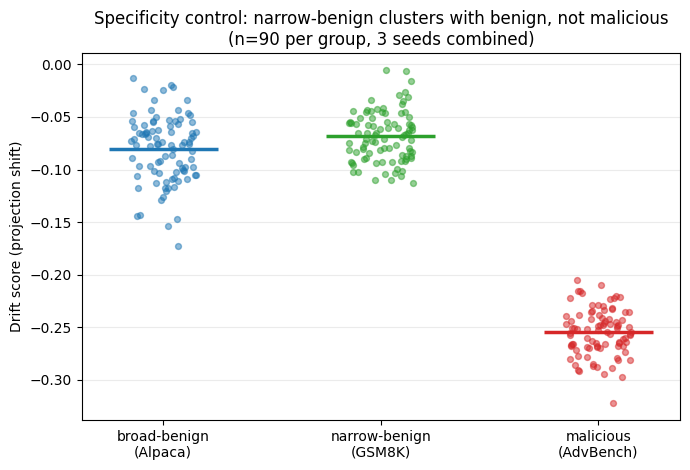

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4.8))
rng = np.random.default_rng(0)

groups = [("broad-benign\n(Alpaca)", broad_benign_combined, "#1f77b4"),
          ("narrow-benign\n(GSM8K)", narrow_benign_combined, "#2ca02c"),
          ("malicious\n(AdvBench)", malicious_combined, "#d62728")]

for i, (label, scores, color) in enumerate(groups):
    jitter = rng.uniform(-0.15, 0.15, size=len(scores))
    ax.scatter([i + j for j in jitter], scores, color=color, s=18, alpha=0.5, zorder=2)
    ax.hlines(np.mean(scores), i - 0.25, i + 0.25, color=color, linewidth=2.5, zorder=3)

ax.set_xticks(range(3)); ax.set_xticklabels([g[0] for g in groups])
ax.set_ylabel("Drift score (projection shift)")
ax.set_title("Specificity control: narrow-benign clusters with benign, not malicious\n(n=90 per group, 3 seeds combined)")
ax.grid(alpha=0.25, axis='y')
fig.tight_layout()

out_dir = f"{RESULTS_DIR}/figures"
os.makedirs(out_dir, exist_ok=True)
fig.savefig(f"{out_dir}/part3c_specificity_control.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{out_dir}/part3c_specificity_control.pdf", bbox_inches="tight")
print(f"Saved: {out_dir}/part3c_specificity_control.png and .pdf")
plt.show()